# Textual Inversion Training Demo

This notebook demonstrates how to use the library code to:
1.  Load a Stable Diffusion pipeline.
2.  Inject a new text embedding (placeholder token).
3.  Setup a dataloader for training.
4.  Iterate over the dataloader.
5.  Run a training loop.
6.  Save the learned embedding.

In [1]:
%cd /workspace/diffusers-ui

/workspace/diffusers-ui


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import torch
from backend.domain import ModelEntry
from backend.model_registry.loader import _load_sana_pipeline

model_id = "/workspace/models/Efficient-Large-Model--SANA1.5_1.6B_1024px_diffusers"

entry = ModelEntry(key='abcd1234', name='sana1.5', base='sana', source=model_id, source_type='local_path', quantization='int8')
pipe = _load_sana_pipeline(entry)

print("Model loaded successfully.")

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Model loaded successfully.


In [14]:
def render_dog():
    generator = torch.Generator(device='cpu')
    generator.manual_seed(42)
    display(pipe(prompt="A photo of a dog", num_inference_steps=10, guidance_scale=4, width=512, height=512, generator=generator).images[0])
    generator.manual_seed(42)
    display(pipe(prompt="A photo of a <sks> dog", num_inference_steps=10, guidance_scale=4, width=512, height=512, generator=generator).images[0])

  0%|          | 0/10 [00:00<?, ?it/s]

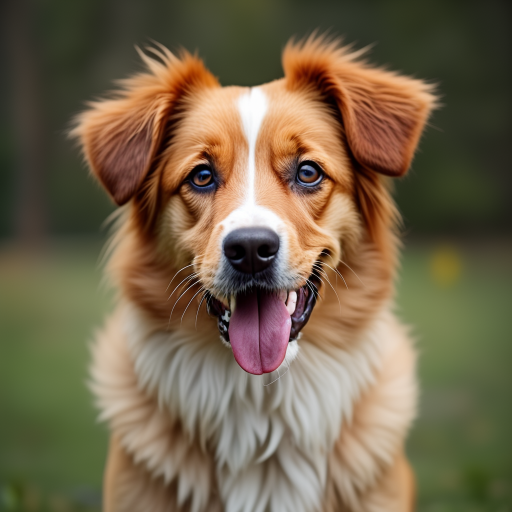

  0%|          | 0/10 [00:00<?, ?it/s]

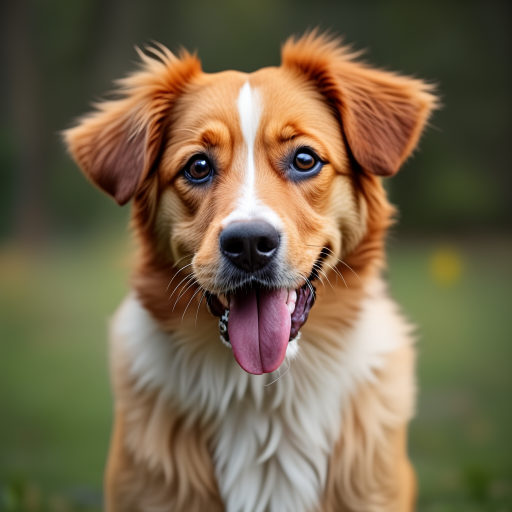

In [15]:
render_dog()

In [6]:
from torch import nn
from backend.training.trainer import (
    _add_tokens, 
    _initialize_embeddings, 
    _embedding_forward_with_offsets, 
    _apply_weight_offsets
)
from backend.training.config import TIConfig

# 2. Inject the new text embedding
config = TIConfig(
    placeholder_token="<sks>",
    initializer_token="dog",
    num_vectors=1,
    model_key="", # Not needed for this manual setup,
    gallery_id=''
)

# Add tokens to tokenizer
placeholder_token_ids = _add_tokens(pipe.tokenizer, config)
pipe.text_encoder.resize_token_embeddings(len(pipe.tokenizer))


The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Embedding(256001, 2304, padding_idx=0)

  0%|          | 0/10 [00:00<?, ?it/s]

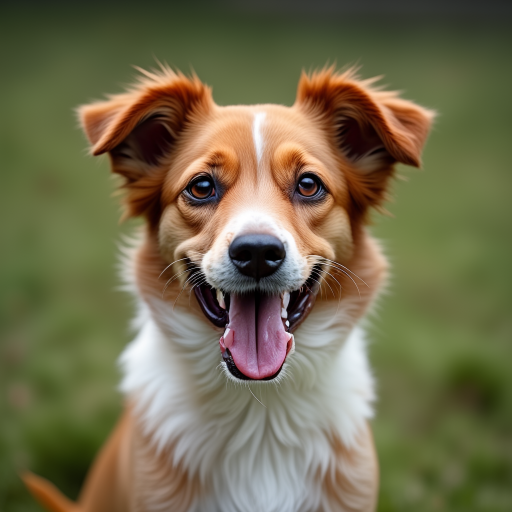

In [7]:
render_dog()

In [7]:

# Initialize embeddings from the initializer token
_initialize_embeddings(pipe.text_encoder, pipe.tokenizer, placeholder_token_ids, config)

# Freeze everything except the new embeddings (via offsets)
pipe.vae.requires_grad_(False)
pipe.transformer.requires_grad_(False)
pipe.text_encoder.requires_grad_(False)



Gemma2Model(
  (embed_tokens): Embedding(256001, 2304, padding_idx=0)
  (layers): ModuleList(
    (0-25): 26 x Gemma2DecoderLayer(
      (self_attn): Gemma2Attention(
        (q_proj): Linear8bitLt(in_features=2304, out_features=2048, bias=False)
        (k_proj): Linear8bitLt(in_features=2304, out_features=1024, bias=False)
        (v_proj): Linear8bitLt(in_features=2304, out_features=1024, bias=False)
        (o_proj): Linear8bitLt(in_features=2048, out_features=2304, bias=False)
      )
      (mlp): Gemma2MLP(
        (gate_proj): Linear8bitLt(in_features=2304, out_features=9216, bias=False)
        (up_proj): Linear8bitLt(in_features=2304, out_features=9216, bias=False)
        (down_proj): Linear8bitLt(in_features=9216, out_features=2304, bias=False)
        (act_fn): GELUTanh()
      )
      (input_layernorm): Gemma2RMSNorm((2304,), eps=1e-06)
      (post_attention_layernorm): Gemma2RMSNorm((2304,), eps=1e-06)
      (pre_feedforward_layernorm): Gemma2RMSNorm((2304,), eps=1e-06)
 

  0%|          | 0/10 [00:00<?, ?it/s]

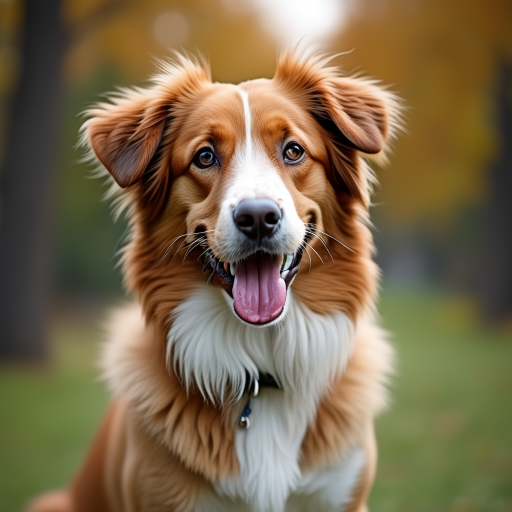

In [9]:
render_dog()

  0%|          | 0/10 [00:00<?, ?it/s]

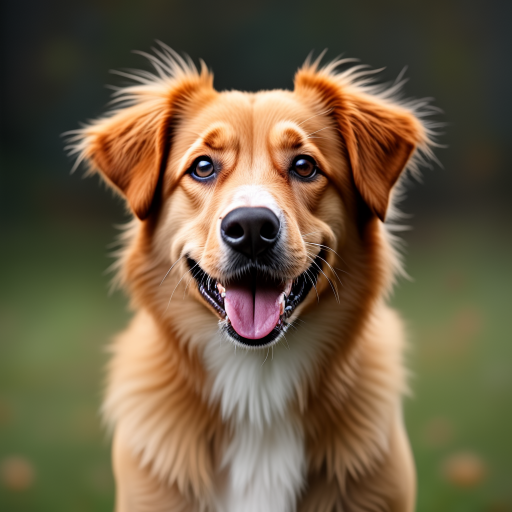

  0%|          | 0/10 [00:00<?, ?it/s]

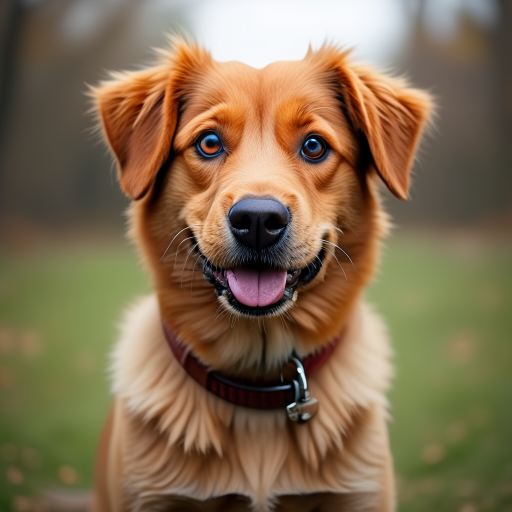

In [8]:

# Create offset parameter
embedding_dim = pipe.text_encoder.get_input_embeddings().weight.shape[1]
offsets = nn.Parameter(
    torch.zeros(len(placeholder_token_ids), embedding_dim, device=pipe.text_encoder.device, dtype=pipe.text_encoder.dtype),
    requires_grad=True,
)

render_dog()

Injected placeholder token '<sks>' (ID: [256000])
Initialized from 'dog'.
Model frozen. Offsets parameter created.


  0%|          | 0/10 [00:00<?, ?it/s]

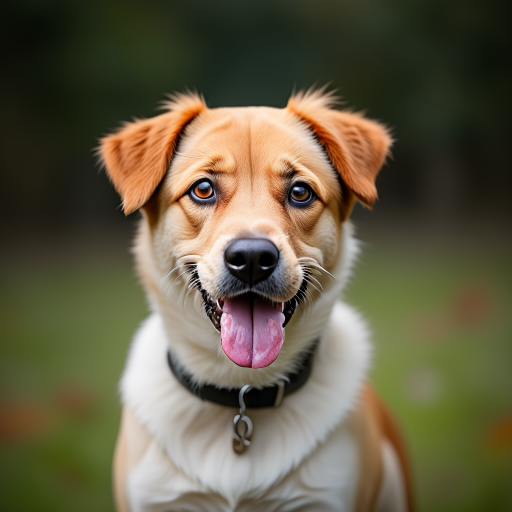

  0%|          | 0/10 [00:00<?, ?it/s]

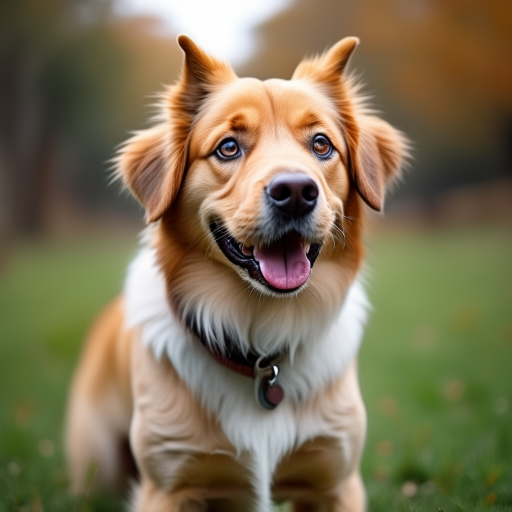

In [9]:

# Register forward hook to apply offsets
embeddings_layer = pipe.text_encoder.get_input_embeddings()
embeddings_layer.training_token_ids = torch.tensor(placeholder_token_ids, device=pipe.text_encoder.device, dtype=torch.long)
embeddings_layer.embedding_offsets_individual = offsets
handle = embeddings_layer.register_forward_hook(_embedding_forward_with_offsets)

print(f"Injected placeholder token '{config.placeholder_token}' (ID: {placeholder_token_ids})")
print(f"Initialized from '{config.initializer_token}'.")
print("Model frozen. Offsets parameter created.")

render_dog()

In [10]:
import os
from pathlib import Path
from torch.utils.data import DataLoader
from backend.training.dataset import TextualInversionDataset
from backend.config import settings

# 3. Setup the dataloader
train_image_dir = Path("/workspace/sana-gore-selected")
train_image_dir.mkdir(exist_ok=True)

# Create a dummy image if the directory is empty
if not any(train_image_dir.glob("*.jpg")):
    raise ValueError("no images")

# Get image names
image_names = [train_image_dir / f.name for f in train_image_dir.glob("*.jpg")]
print(f"Found {len(image_names)} images in '{train_image_dir}'.")

# Create dataset
dataset = TextualInversionDataset(
    image_names=image_names,
    tokenizer=pipe.tokenizer,
    placeholder_token=config.placeholder_token,
    size=config.resolution,
    repeats=config.repeats,
    learnable_property=config.learnable_property,
    class_prompt=config.class_prompt,
)

# Create dataloader
dataloader = DataLoader(dataset, batch_size=config.train_batch_size, shuffle=True)
print(f"Dataloader created with batch size {config.train_batch_size}.")

Found 120 images in '/workspace/sana-gore-selected'.
Dataloader created with batch size 1.


  0%|          | 0/10 [00:00<?, ?it/s]

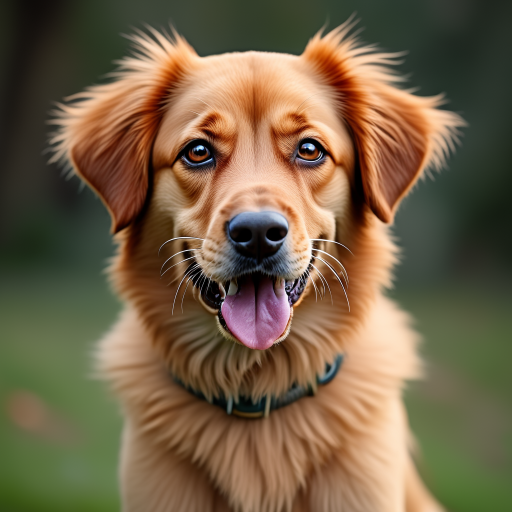

In [13]:
render_dog()

In [11]:
pipe.tokenizer.model_max_length = 300

In [12]:
# 4. Iterate the first batch and show contents
print("Fetching the first batch...")
batch = next(iter(dataloader))

print(f"Batch keys: {batch.keys()}")
print(f"pixel_values shape: {batch['pixel_values'].shape}")
print(f"input_ids shape: {batch['input_ids'].shape}")

# Decode the input_ids to see the prompt
decoded_text = pipe.tokenizer.decode(batch['input_ids'][0])
print(f"Decoded prompt: {decoded_text}")

Fetching the first batch...
tokenzining text: a photo of a cool <sks>
Batch keys: dict_keys(['pixel_values', 'attention_mask', 'input_ids'])
pixel_values shape: torch.Size([1, 3, 512, 512])
input_ids shape: torch.Size([1, 300])
Decoded prompt: <bos>a photo of a cool <sks><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pa

In [ ]:
render_dog()

Starting training loop...
tokenzining text: a photo of a clean <sks>
tensor([840], device='cuda:0')
Step 1, Loss: 1.8799


  0%|          | 0/10 [00:00<?, ?it/s]

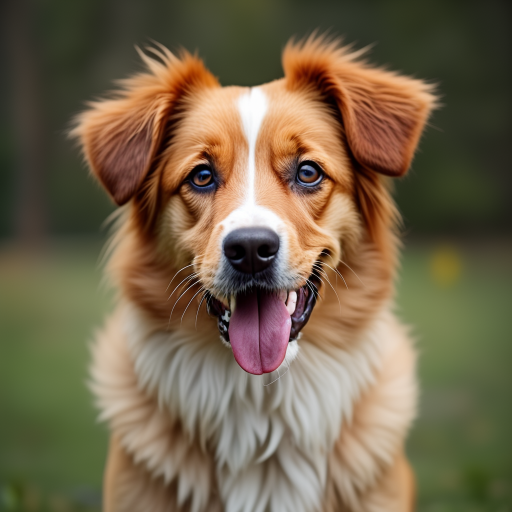

  0%|          | 0/10 [00:00<?, ?it/s]

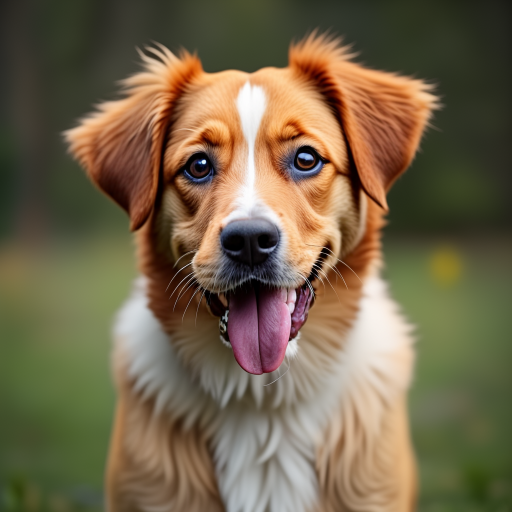

tokenzining text: a good photo of a <sks>
tensor([976], device='cuda:0')
Step 2, Loss: 6.5399
tokenzining text: a photo of a cool <sks>
tensor([442], device='cuda:0')
Step 3, Loss: 1.7970
tokenzining text: a photo of the nice <sks>
tensor([712], device='cuda:0')
Step 4, Loss: 1.5920
tokenzining text: a good photo of the <sks>
tensor([961], device='cuda:0')
Step 5, Loss: 4.4552
tokenzining text: a photo of one <sks>
tensor([636], device='cuda:0')
Step 6, Loss: 1.9377
tokenzining text: a photo of a dirty <sks>
tensor([952], device='cuda:0')
Step 7, Loss: 1.9607
tokenzining text: a photo of the cool <sks>
tensor([803], device='cuda:0')
Step 8, Loss: 1.9382
tokenzining text: a photo of a small <sks>
tensor([409], device='cuda:0')
Step 9, Loss: 1.6304
tokenzining text: a bright photo of the <sks>
tensor([948], device='cuda:0')
Step 10, Loss: 4.2327
tokenzining text: a photo of my <sks>
tensor([319], device='cuda:0')
Step 11, Loss: 1.2077
tokenzining text: a photo of the large <sks>
tensor([

  0%|          | 0/10 [00:00<?, ?it/s]

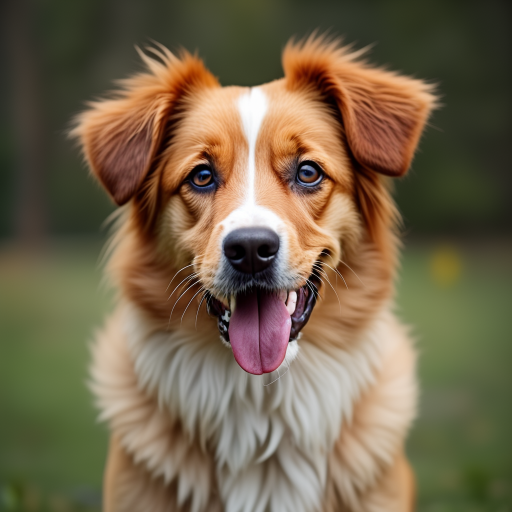

  0%|          | 0/10 [00:00<?, ?it/s]

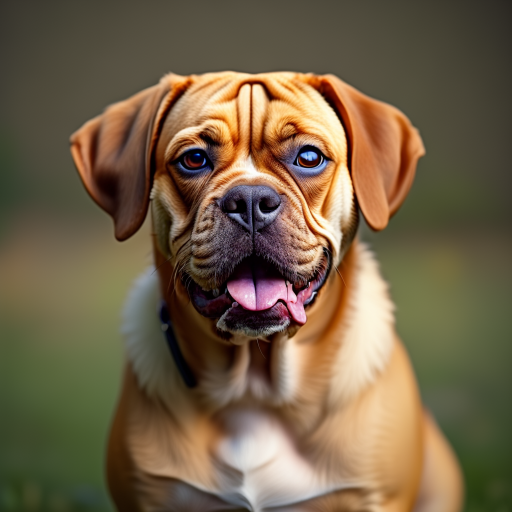

tokenzining text: a photo of my <sks>
tensor([749], device='cuda:0')
Step 52, Loss: 1.1417
tokenzining text: a photo of a clean <sks>
tensor([885], device='cuda:0')
Step 53, Loss: 2.6197
tokenzining text: a close-up photo of a <sks>
tensor([324], device='cuda:0')
Step 54, Loss: 1.6176
tokenzining text: a photo of the cool <sks>
tensor([253], device='cuda:0')
Step 55, Loss: 1.6961
tokenzining text: a photo of the weird <sks>
tensor([386], device='cuda:0')
Step 56, Loss: 1.6700
tokenzining text: a cropped photo of the <sks>
tensor([51], device='cuda:0')
Step 57, Loss: 1.4600
tokenzining text: a photo of the cool <sks>
tensor([742], device='cuda:0')
Step 58, Loss: 1.8976
tokenzining text: a photo of the weird <sks>
tensor([546], device='cuda:0')
Step 59, Loss: 1.7399
tokenzining text: a photo of the cool <sks>
tensor([147], device='cuda:0')
Step 60, Loss: 1.4540
tokenzining text: a photo of one <sks>
tensor([711], device='cuda:0')
Step 61, Loss: 1.8317
tokenzining text: a photo of my <sks

  0%|          | 0/10 [00:00<?, ?it/s]

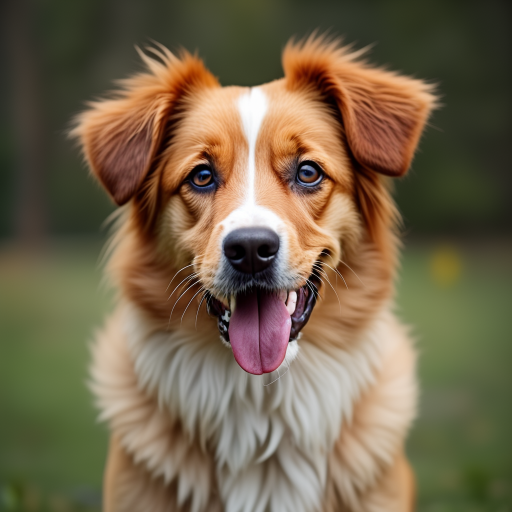

  0%|          | 0/10 [00:00<?, ?it/s]

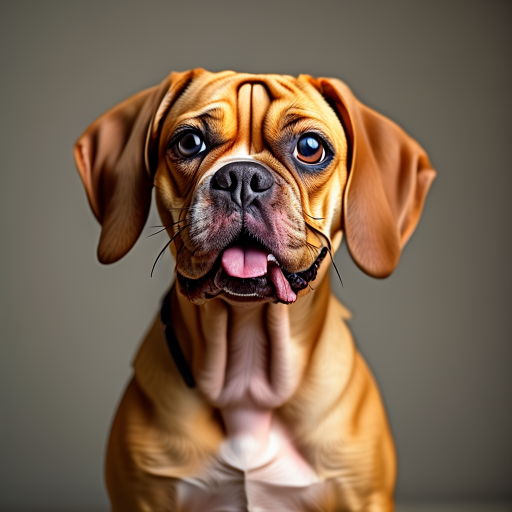

tokenzining text: a photo of one <sks>
tensor([419], device='cuda:0')
Step 102, Loss: 2.6750
tokenzining text: a photo of the nice <sks>
tensor([816], device='cuda:0')
Step 103, Loss: 1.3444
tokenzining text: a good photo of a <sks>
tensor([473], device='cuda:0')
Step 104, Loss: 1.7463
tokenzining text: a cropped photo of the <sks>
tensor([964], device='cuda:0')
Step 105, Loss: 2.6874
tokenzining text: a rendering of a <sks>
tensor([469], device='cuda:0')
Step 106, Loss: 1.5109
tokenzining text: a photo of a clean <sks>
tensor([305], device='cuda:0')
Step 107, Loss: 1.5012
tokenzining text: a rendition of a <sks>
tensor([311], device='cuda:0')
Step 108, Loss: 1.6558
tokenzining text: a photo of one <sks>
tensor([756], device='cuda:0')
Step 109, Loss: 1.7359
tokenzining text: a close-up photo of a <sks>
tensor([136], device='cuda:0')
Step 110, Loss: 1.5655
tokenzining text: a close-up photo of the <sks>
tensor([378], device='cuda:0')
Step 111, Loss: 1.6988
tokenzining text: a good photo

  0%|          | 0/10 [00:00<?, ?it/s]

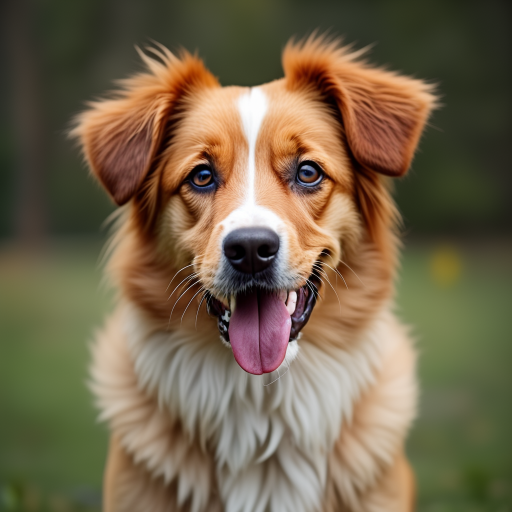

  0%|          | 0/10 [00:00<?, ?it/s]

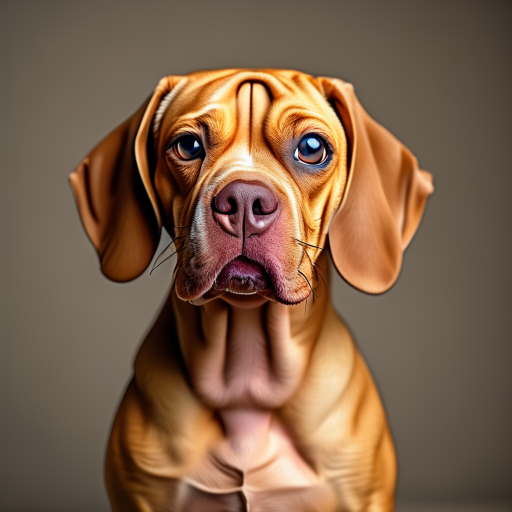

tokenzining text: a rendition of the <sks>
tensor([730], device='cuda:0')
Step 152, Loss: 1.8735
tokenzining text: a close-up photo of a <sks>
tensor([166], device='cuda:0')
Step 153, Loss: 1.6502
tokenzining text: the photo of a <sks>
tensor([813], device='cuda:0')
Step 154, Loss: 2.6769
tokenzining text: a photo of my <sks>
tensor([187], device='cuda:0')
Step 155, Loss: 1.6072
tokenzining text: a close-up photo of the <sks>
tensor([385], device='cuda:0')
Step 156, Loss: 1.4707
tokenzining text: a photo of a cool <sks>
tensor([909], device='cuda:0')
Step 157, Loss: 2.4271
tokenzining text: a photo of the large <sks>
tensor([160], device='cuda:0')
Step 158, Loss: 2.0890
tokenzining text: a photo of a clean <sks>
tensor([616], device='cuda:0')
Step 159, Loss: 1.7646
tokenzining text: a rendering of a <sks>
tensor([727], device='cuda:0')
Step 160, Loss: 2.0227
tokenzining text: a rendition of the <sks>
tensor([907], device='cuda:0')
Step 161, Loss: 3.6161
tokenzining text: a cropped phot

  0%|          | 0/10 [00:00<?, ?it/s]

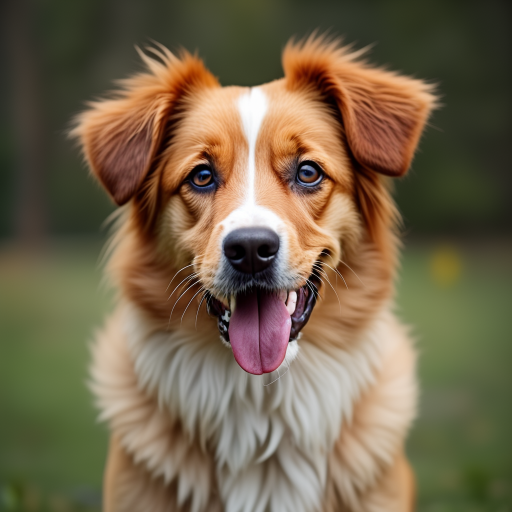

  0%|          | 0/10 [00:00<?, ?it/s]

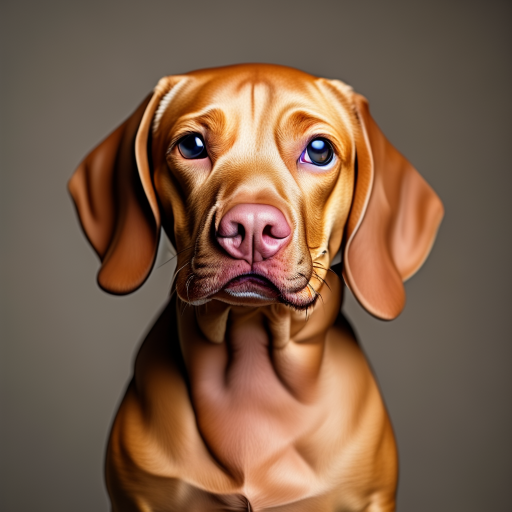

tokenzining text: a photo of the cool <sks>
tensor([689], device='cuda:0')
Step 202, Loss: 1.6020
tokenzining text: a photo of the small <sks>
tensor([592], device='cuda:0')
Step 203, Loss: 1.6690
tokenzining text: a photo of a <sks>
tensor([189], device='cuda:0')
Step 204, Loss: 1.7518
tokenzining text: a photo of a cool <sks>
tensor([675], device='cuda:0')
Step 205, Loss: 1.8102
tokenzining text: a photo of the large <sks>
tensor([303], device='cuda:0')
Step 206, Loss: 1.6359
tokenzining text: a cropped photo of a <sks>
tensor([905], device='cuda:0')
Step 207, Loss: 2.8727
tokenzining text: a photo of the large <sks>
tensor([739], device='cuda:0')
Step 208, Loss: 2.4620
tokenzining text: a cropped photo of a <sks>
tensor([843], device='cuda:0')
Step 209, Loss: 2.3635
tokenzining text: a rendition of the <sks>
tensor([708], device='cuda:0')
Step 210, Loss: 1.5578
tokenzining text: a photo of the large <sks>
tensor([900], device='cuda:0')
Step 211, Loss: 3.8801
tokenzining text: a phot

KeyboardInterrupt: 

In [16]:
import torch.nn.functional as F
from torch.optim import AdamW

# 5. Run 1 epoch of training
optimizer = AdamW([offsets], lr=config.learning_rate)
pipe.text_encoder.train()

device = pipe.device
print("Starting training loop...")
for epoch in range(1): # Just 1 epoch for demo
    for i, batch in enumerate(dataloader):
        # Move batch to device
        pixel_values = batch["pixel_values"].to(device, dtype=torch.float16)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch['attention_mask'].to(device)

        # 1. Encode images to latents
        with torch.no_grad():
            # sana
            encoded = pipe.vae.encode(pixel_values.to(device, dtype=pipe.vae.dtype))
            latents = encoded.latent if hasattr(encoded, "latent") else encoded.latent_dist.sample()

        # 2. Add noise
        noise = torch.randn_like(latents)
        bsz = latents.shape[0]
        timesteps = torch.randint(
            0, pipe.scheduler.config.num_train_timesteps, (bsz,), device=latents.device
        )
        print(timesteps)
        noisy_latents = pipe.scheduler.add_noise(latents, noise, timesteps)

        # 3. Encode text
        encoder_hidden_states = pipe.text_encoder(input_ids, attention_mask=attention_mask)[0]

        # 4. Predict noise
        model_pred = pipe.transformer(hidden_states=noisy_latents, encoder_hidden_states=encoder_hidden_states, timestep=timesteps, encoder_attention_mask=attention_mask).sample

        # 5. Compute loss (MSE between predicted and actual noise)
        target = noise # For epsilon prediction
        loss = F.mse_loss(model_pred.float(), target.float(), reduction="mean")

        # 6. Backprop
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        print(f"Step {i+1}, Loss: {loss.item():.4f}")

        if i%50 == 0:

            render_dog()

print("Training loop finished.")

In [ ]:
import safetensors.torch

# 6. Save the embeddings to disk
# Merge offsets into the original embeddings
merged = _apply_weight_offsets(
    torch.tensor(placeholder_token_ids, device=text_encoder.device), 
    text_encoder.get_input_embeddings(), 
    offsets
)
embeds = merged.detach().cpu()

# Save as safetensors
output_path = "learned_embeds.safetensors"
embed_dict = {config.placeholder_token: embeds}
safetensors.torch.save_file(embed_dict, output_path, metadata={"format": "pt"})

print(f"Embeddings saved to '{output_path}'.")
print(f"Tensor shape: {embeds.shape}")